# DataIO: Erica によるデータ再構成

SMILE-2+ の生データ(μTPC のアノード/カソード + HA シンチレータ)を EricaNext の解析チェーンに通し、
1 イベント 1 行の再構成ツリー `Reconstruct/single_hit` を作るまでを説明します。
ここで作るツリーが、バックプロジェクションなど以降の解析の入力になります。

各モジュールの中身は `modules/` 以下のノートブックで個別に解説しています。

> このチェーンは SMILE_tool_box_v2.20 の出力(`haboc_tmp_0.root` の `Reconstruct/s2t`)と
> ビット単位で一致することを確認済みです(経緯は `docs/per02_comparison_log.md`)。

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

設定ファイル `config/smile2p_20190701_Per02.json` に、データの場所(`{data_top}` はデータの置き場に置き換わる)と
各モジュールのパラメータが書かれています。データが見つかるか確認します(`MISSING` なら上のコマンドでコピー)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. 解析チェーン

チェーンの順序は SMILE_tool_box の `setting.mac` の `[Def]` と同じです。

| 順 | EricaNext | SMILE_tool_box | 役割 | 解説 |
|---|---|---|---|---|
| 0 | `ReadData` | `RawRead2p` | 生データ読み込み・検出器間のイベント同期 | `modules/ReadData` |
| 1 | `CalcFADC` | `CalcFADC` | TPC の FADC 波形 → 電荷 | `modules/CalcFADC` |
| 2 | `TPC_Calibration` | `TPC_Calibration` | アノード×カソード同時計数 → 反跳電子エネルギー `Ke` | `modules/TPC_Calibration` |
| 3 | `HA_CenterGravity` | `HA_Center_Gravity` | シンチ PMT の重心 | `modules/HA_CenterGravity` |
| 4 | `HA_Calc` | `HA_Calc_s2` | ピクセル同定・較正 → `Eg`, 吸収点 `Pg` | `modules/HA_Calc` |
| 5 | `TOT_Skewness` | `TOT_Skewness_Analysis` | 電子飛跡 → 散乱点 `Pe`, 方向 `Ve` | `modules/TOT_Skewness` |
| 6 | `Reconstruct` | `Reconstruct` | 1 イベント 1 行の再構成ツリー | `modules/Reconstruct` |
| — | `RawTreeWriter` | — | `ReadData` の直後につなぎ、同期した生データを TTree に書き出す(較正・診断用) | `modules/RawTreeWriter` |

どのモジュールも「失敗したらチェーンを止める」のではなく、**センチネル値(`0xffffffff`)を入れて続行**します。
出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。各モジュールの処理を確かめる図は、
`RawTreeWriter` の生データツリーや再構成ツリーから後で描きます(`modules/` 以下)。

チェーンの順番と各モジュールのパラメータは、設定ファイル `config/smile2p_20190701_Per02.json` に書かれています。
値は参照の実行で実際に使われたもの(`HabocStatus.scl`)です。`_` で始まるキーは説明用のコメントです。

In [3]:
print((REPO / "config" / f"{CONFIG}.json").read_text())

{
  "_comment": [
    "SMILE-2+ 20190701 Per02 ground-calibration run.",
    "Values follow the SMILE_tool_box_v2.20 reference run",
    "(sm2+_cal_rootdata/20190701_Per02/setting.mac and HabocStatus.scl).",
    "{data_top} is replaced by the data directory ($SMILE2P_DATA, ~/smile2p_data or the server directory)."
  ],
  "period": "Per02",
  "reference": {
    "setting_mac": "/home/onoda/hikaru3_analysis2/sm2+_cal_rootdata/20190701_Per02/setting.mac",
    "root": "/home/onoda/hikaru3_analysis2/sm2+_cal_rootdata/20190701_Per02/haboc_tmp_0.root"
  },
  "chain": [
    "ReadData",
    "CalcFADC",
    "TPC_Calibration",
    "HA_CenterGravity",
    "HA_Calc",
    "TOT_Skewness",
    "Reconstruct"
  ],
  "parameters": {
    "ReadData": {
      "data_dir": "{data_top}/Per02_ETCC",
      "reverse_TPC": true
    },
    "CalcFADC": {
      "_setting_mac": "[CalcFADC] Base_min-Base_max = 0-30, Charge_threshold : 20",
      "base_window": 30.0,
      "threshold": 20.0
    },
    "TPC_Calibration": 

## 3. チェーンの実行

チェーンは `run_script/run_chain.py` で実行します。ターミナルでは次のように打ちます。

```bash
cd run_script
python3 run_chain.py smile2p_20190701_Per02 -o per02_out.root            # 全イベント(約 1 時間)
python3 run_chain.py smile2p_20190701_Per02 -o test.root -n 50000        # 先頭 50000 イベント
```

`run_chain.py` がしていることは、設定ファイルの順にモジュールを ANLNext のチェーンにつないで実行するだけです:

```python
import anlnext, EricaPy as th, ericanext_config as ec
cfg = ec.load("smile2p_20190701_Per02")
a = anlnext.AnalysisChain()
a.chain(th.SaveFile);  a.with_parameters({"filename": "test.root"})
for m in cfg["chain"]:                          # ReadData, CalcFADC, ..., Reconstruct
    a.chain(getattr(th, m))
    a.with_parameters(cfg["parameters"][m])     # 設定ファイルのパラメータ
a.run(50000)
```

ノートブックからも同じコマンドを `subprocess` で実行します(`CalcFADC` は `std::thread` を使うため、
Jupyter のカーネル内でチェーンを直接動かすとカーネルごと落ちることがあります)。
ここでは先頭 50000 イベントを処理し(数分)、出力は `tutorials/cache/` に置いて他のチュートリアルでも使います。
パラメータを変えて試すときは、設定ファイルをコピーして値を書き換え、そのファイル名(またはパス)を渡します。

In [4]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_50000.root -n 50000


## 4. 出力ファイルの中身

出力ファイルには TTree だけが入っています。解析で使うのは `Reconstruct/single_hit` です
(`TOT_Skewness/tot_skewness` は電子飛跡の結果だけのツリー)。

In [5]:
f = ROOT.TFile.Open(str(OUT))
for key in f.GetListOfKeys():
    for obj in key.ReadObj().GetListOfKeys():
        print(f"{key.GetName()}/{obj.GetName()}  ({obj.GetClassName()})")

TOT_Skewness/tot_skewness  (TTree)
Reconstruct/single_hit  (TTree)


## 5. 再構成ツリー `Reconstruct/single_hit`

**全イベントで 1 行**(参照の `Reconstruct/s2t` と同じ並び)です。主な分岐:

| 分岐 | 内容 |
|---|---|
| `err_flag` | 0 = シングルヒットとして再構成できた(Ee・Eg・電子方向 Ve_TRA が全部有効) |
| `Eg`, `Ke` | 散乱ガンマ線(シンチ)・反跳電子(TPC)のエネルギー [keV](`Ke` は参照の `Ee`) |
| `Pg` | シンチでの吸収点 [mm] |
| `Pe_TRA`, `Ve_TRA`, `Len_TRA` | TPC での散乱点・電子の方向・飛程(`Pe_TRA`, `Ve_TRA` は 6 要素で、使うのは先頭 3 つ) |
| `Track_Min`, `Track_Max` | 飛跡を囲む箱の角 [mm] |
| `phi_kin`, `psi_kin`, `alpha_kin` | エネルギーから求めた散乱角・反跳角・両者のなす角 [deg] |
| `HA_Pixel`, `HA_Gravity`, `HA_MDF` | シングルヒットのピクセル(HA 番号・PMT・x・y)、重心、MDF 変換後の位置 |
| `sevt_id`, `event_id` | 通し番号(参照の `SEvt_ID`)・トリガ番号(参照の `anode_id`) |

> **注意**: 参照と同じく、`err_flag != 0` の行の `Eg`/`Ke`/`Pg` などには
> **前のイベントの値がそのまま残っています**。解析には必ず `err_flag == 0` の行だけを使ってください。

ROOT の `RDataFrame` で `err_flag == 0` の行だけを選び、numpy の配列にします。

In [6]:
df = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT))
print("rows:", df.Count().GetValue())
d = df.Filter("err_flag == 0").AsNumpy(["Eg", "Ke", "Pe_TRA", "Len_TRA"])
Eg, Ke, Len = d["Eg"], d["Ke"], d["Len_TRA"]
Pe = vec(d["Pe_TRA"])[:, :3]
print("err_flag == 0:", len(Eg))

rows: 50000


err_flag == 0: 26697


## 6. 再構成量を見る

入射ガンマ線のエネルギーは `E0 = Eg + Ke` です。

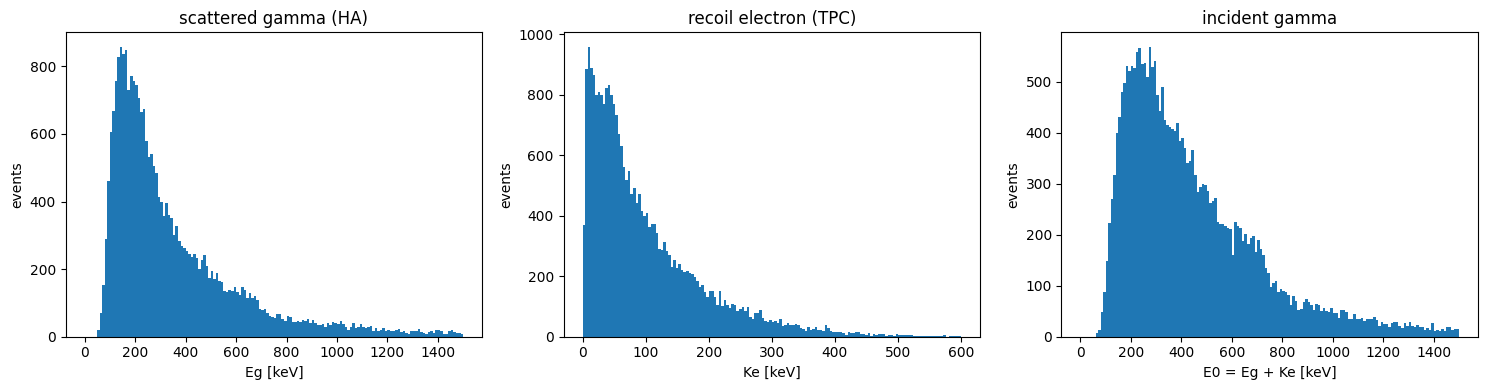

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(Eg, bins=150, range=(0, 1500)); ax[0].set_xlabel("Eg [keV]"); ax[0].set_title("scattered gamma (HA)")
ax[1].hist(Ke, bins=150, range=(0, 600));  ax[1].set_xlabel("Ke [keV]"); ax[1].set_title("recoil electron (TPC)")
ax[2].hist(Eg + Ke, bins=150, range=(0, 1500)); ax[2].set_xlabel("E0 = Eg + Ke [keV]"); ax[2].set_title("incident gamma")
for x in ax: x.set_ylabel("events")
fig.tight_layout(); plt.show()

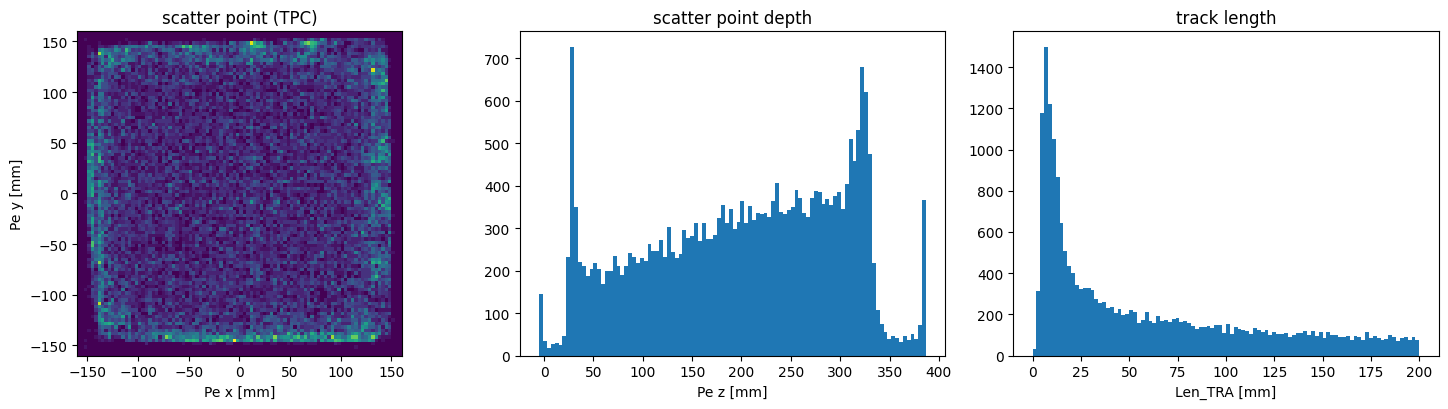

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].hist2d(Pe[:, 0], Pe[:, 1], bins=96, range=[[-160, 160], [-160, 160]])
ax[0].set_xlabel("Pe x [mm]"); ax[0].set_ylabel("Pe y [mm]"); ax[0].set_title("scatter point (TPC)"); ax[0].set_aspect("equal")
ax[1].hist(Pe[:, 2], bins=100); ax[1].set_xlabel("Pe z [mm]"); ax[1].set_title("scatter point depth")
ax[2].hist(Len, bins=100, range=(0, 200)); ax[2].set_xlabel("Len_TRA [mm]"); ax[2].set_title("track length")
fig.tight_layout(); plt.show()

## 次のステップ

- 各モジュールの詳しい説明: `modules/<モジュール名>/`
- イベント選択: `../EventSelection/`
- この出力を使ったイメージング: `../Backprojection_caldata/`
- 全イベントを処理するには `-n` を付けずに `run_chain.py` を実行(約 1 時間)。
  他の期間は設定ファイル `smile2p_20190701_Per03` など(ドリフト速度の表はその期間のもの)。